# EXP-01 — Normative Audit, Decision-Driven EDA and End-to-End Baseline

**TPI Visual Scene Understanding — UTN Artificial Intelligence, Spring 2026 — Group 2**

**Hypothesis (EXP-01).** A baseline pipeline whose `SceneJSON` contract is verified against `scene_schema.json`, evaluated with the exact LVIS federated policy, and whose 60 `questions_dev.jsonl` prompts are resolved by a deterministic engine, secures the 15% JSON-consistency term and establishes an auditable, leakage-free reference point for every later experiment.

**Pipeline under test** (`Perception → Segmentation → Representation → Reasoning`):

| Stage | Component | Module |
|---|---|---|
| Perception | OWLv2 Base (`google/owlv2-base-patch16-ensemble`), prompts = the 120 official names, per-class NMS 0.5 | `src/perception_detectors.py` |
| Segmentation | SAM2.1 Base+ (`facebook/sam2.1-hiera-base-plus`), one box prompt per detection, `multimask_output=False`, non-empty mask guarantee | `src/segmentation_sam2.py` |
| Representation | Column-major RLE, centroid, `area_ratio`, 3×3 position, size, dominant color, symmetric relations | `src/scene_builder.py` |
| Reasoning | Deterministic QA engine (`questions`) + rule-based text interpreter feeding the same engine (`questions_llm`) | `src/qa_engine.py` |
| Evaluation | LVIS federated evaluator (IoU ≥ 0.5) + 8-test contract suite | `src/lvis_evaluator.py` |

**Controlled-experiment discipline.** EXP-01 deliberately uses *no* LVIS prompt aliases, *no* chunked prompting and *no* tiling: those are the variables of EXP-02A/B, and introducing them here would make the later ablations uninterpretable. The only tuned parameter is a single global score threshold, selected on `CAL` and only *reported* on `VAL`.

**Epistemic convention used throughout.** *Observed* = detector boxes/scores and SAM2 masks; *derived* = `area_ratio`, `centroid`, `position`, `size`, `dominant_color`, `relations`; *unknown* = answered `unsupported` / `insufficient_information`. `annotations.json` is read in this notebook **only** for EDA and evaluation — inference functions never receive it (verified by Test 1 of the suite with an audit hook on `open()`).

**Compute note.** This notebook was executed on a CPU-only workstation (no CUDA device). Latencies are therefore CPU latencies and VRAM is reported as *N/A (CPU)*; suite Test 8 (VRAM budget) stays `SKIPPED` until the Kaggle GPU run.

In [1]:
import csv, json, os, platform, sys, time
from collections import Counter, defaultdict
from pathlib import Path

os.environ.setdefault("HF_HUB_OFFLINE", "1")
REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from PIL import Image

from src import config_and_seeds as cfg
from src import lvis_evaluator as ev
from src import pipeline as pl
from src import qa_engine as qa
from src import scene_builder as sb
from src.perception_detectors import filter_detections
from scripts.build_gt_oracle import build_gt_scenes

cfg.set_global_seeds(cfg.SEED)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
PATHS = cfg.get_dataset_paths()
SCHEMA = json.loads(PATHS.schema.read_text(encoding="utf-8"))
ANNOTATIONS = json.loads(PATHS.annotations.read_text(encoding="utf-8"))  # EDA/evaluation only, never inference
QUESTIONS = [json.loads(l) for l in PATHS.questions_dev.read_text(encoding="utf-8").splitlines() if l.strip()]
CACHE_DIR = REPO / "artifacts" / "cache_exp01"
print(f"Python {platform.python_version()} | torch {torch.__version__} | transformers {transformers.__version__}")
print(f"CUDA available: {torch.cuda.is_available()} | CPU threads: {torch.get_num_threads()} | SEED={cfg.SEED}")
print(f"Dataset root: {PATHS.root}")

/home/fede/Ingenieria_en_Sistemas/Inteligencia Artificial/Tp/TPDe0/TPI-IA/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python 3.12.12 | torch 2.15.0+cpu | transformers 5.21.0
CUDA available: False | CPU threads: 2 | SEED=42
Dataset root: /home/fede/Ingenieria_en_Sistemas/Inteligencia Artificial/Tp/dataset


**Analysis — environment and reproducibility.**

- The run is fully pinned: Python 3.12, `torch` CPU build and `transformers` 5.x (exact versions in `requirements.txt`), `SEED = 42` applied to `random`, `numpy` and `torch` (`cudnn.deterministic` would also be forced on a GPU). `HF_HUB_OFFLINE=1` guarantees the weights come from the local cache that produced the inference caches, not from a silently updated Hub revision.
- `CUDA available: False` is the expected state of this workstation. It has two consequences that the rest of the notebook makes explicit instead of hiding: (1) all `ms/img` values are CPU latencies and are **not** representative of the Kaggle T4 budget, and (2) VRAM cannot be measured, so it is reported as `N/A (CPU)` rather than as a fabricated `0`.
- `annotations.json` is loaded here *only* for EDA and evaluation. The inference entry point (`src/pipeline.infer_scene`) receives an image path plus the models, so the ground truth is physically outside its call graph; Section 4 proves this with the suite's audit hook.

---
## Section 1 — Normative audit: `scene_schema.json`, `sample_submission.csv` and the CAL/VAL partition

Before measuring anything we pin down the contract the Kaggle metric consumes. Every later number in this notebook is meaningless if a single row of the submission fails schema validation (the whole row would lose its 15% JSON-consistency contribution and its detections).

In [2]:
obj_schema = SCHEMA["properties"]["objects"]["items"]
props = obj_schema["properties"]
rel_schema = SCHEMA["properties"]["relations"]
qa_def = SCHEMA["$defs"]["questionAnswer"]
audit = pd.DataFrame([
    ("root.required", SCHEMA["required"]),
    ("root optional (dev rows)", [k for k in SCHEMA["properties"] if k not in SCHEMA["required"]]),
    ("objects.maxItems", SCHEMA["properties"]["objects"]["maxItems"]),
    ("object.required (9)", obj_schema["required"]),
    ("bbox", json.dumps(props["bbox"])),
    ("area_ratio", json.dumps(props["area_ratio"])),
    ("position.enum", props["position"]["enum"]),
    ("size.enum", props["size"]["enum"]),
    ("relations.maxItems", rel_schema["maxItems"]),
    ("relation.predicate.enum", rel_schema["items"]["properties"]["predicate"]["enum"]),
    ("question.type.enum", qa_def["properties"]["type"]["enum"]),
    ("question.required", qa_def["required"]),
    ("normalized_answer", json.dumps(qa_def["properties"]["normalized_answer"])),
    ("questions_llm extra required", SCHEMA["$defs"]["questionAnswerLLM"]["allOf"][1]["required"]),
], columns=["contract", "value"])
print(audit.to_string(index=False, max_colwidth=110))

                    contract                                                                                                          value
               root.required                                                                                    [image, objects, relations]
    root optional (dev rows)                                                                                     [questions, questions_llm]
            objects.maxItems                                                                                                            300
         object.required (9)                                [id, category_id, confidence, bbox, mask, centroid, area_ratio, position, size]
                        bbox {"type": "array", "prefixItems": [{"type": "number"}, {"type": "number"}, {"type": "number"}, {"type": "num...
                  area_ratio                                                        {"type": "number", "exclusiveMinimum": 0, "maximum": 1}
               posit

**Analysis — what the schema really enforces (and the traps it hides).**

1. **Field names are not negotiable.** The root requires exactly `image`, `objects`, `relations`; `questions`/`questions_llm` are optional at schema level but mandatory for the 20 benchmark rows (README). Each object requires the nine keys listed — notably `area_ratio` (not `relative_area`) and the root list is `relations` (not `spatial_relations`). `additionalProperties: true` lets us attach lineage (`detector_source`, `dominant_color`, `category_name`, `mask_fallback`) without breaking validation.
2. **`area_ratio` has `exclusiveMinimum: 0`.** A single empty mask makes the whole row invalid. This is why `build_object` routes every mask through `ensure_non_empty_mask` (SAM2 output → bbox fill → single pixel) and records the fallback for traceability.
3. **`bbox` is a 4-number array** interpreted by the metric as `xyxy`, while `annotations.json` stores COCO `xywh`; the evaluator converts GT, never predictions.
4. **Hard caps:** 300 objects and 20,000 relations per scene. With full pairwise directional relations, 95 objects already yield up to 26,790 directed triples, so `build_relations` caps both the participating objects (top-95 by confidence) and the triple count (< 20,000, symmetric pairs emitted atomically).
5. **`normalized_answer` is `oneOf` integer ≥ 0 / non-empty string.** The schema would accept `"2"` for a count, but the benchmark compares typed values; the engine therefore emits a Python `int` for every `count` and the suite's Test 4 asserts `type(...) is int`.
6. **`questions_llm` = `questionAnswer` + a required `interpreted_query` object** — the structured trace of how the question text was understood, which must exist even before the EXP-04 SLM is plugged in.

In [3]:
sample_rows = ev.read_submission(PATHS.sample_submission)
test_meta = pd.read_csv(PATHS.test_images)
ids = [r["image_id"] for r in sample_rows]
dev_ids = [i for i in ids if i.startswith("tpi_")]
qa_keys = sorted({q["image_file"].rsplit(".", 1)[0] for q in QUESTIONS})
print(f"rows={len(sample_rows)} | test={sum(i.startswith('test_') for i in ids)} | dev={len(dev_ids)}")
print("test order == test_images.csv:", ids[:60] == test_meta["image_id"].tolist())
print("dev rows == questions_dev images:", sorted(dev_ids) == qa_keys, "| dev order:", dev_ids)
example = json.loads(sample_rows[0]["SceneJSON"])
obj = example["objects"][0]
decoded = sb.decode_rle(obj["mask"])
print("example object:", {k: obj[k] for k in ("bbox", "centroid", "area_ratio", "position", "size")})
print("mask counts head:", obj["mask"]["counts"][:3], "| decoded pixels:", int(decoded.sum()),
      "| pixel (0,0) set:", bool(decoded[0, 0]), "| re-encoded equal:", sb.encode_rle(decoded) == obj["mask"])
print("dev row keys:", list(json.loads(sample_rows[-1]["SceneJSON"]).keys()))
sample_report = ev.run_full_verification_suite(PATHS.sample_submission, require_qa=False, raise_on_fail=False)
print(sample_report)

rows=80 | test=60 | dev=20
test order == test_images.csv: True
dev rows == questions_dev images: True | dev order: ['tpi_0001', 'tpi_0002', 'tpi_0003', 'tpi_0004', 'tpi_0005', 'tpi_0006', 'tpi_0007', 'tpi_0008', 'tpi_0009', 'tpi_0010', 'tpi_0011', 'tpi_0012', 'tpi_0014', 'tpi_0015', 'tpi_0019', 'tpi_0020', 'tpi_0022', 'tpi_0023', 'tpi_0024', 'tpi_0025']
example object: {'bbox': [0, 0, 1, 1], 'centroid': [0, 0], 'area_ratio': 3.6764705882352942e-06, 'position': 'top_left', 'size': 'small'}
mask counts head: [0, 1, 271999] | decoded pixels: 1 | pixel (0,0) set: True | re-encoded equal: True
dev row keys: ['image', 'objects', 'relations', 'questions', 'questions_llm']


[SKIPPED] test_1_blind_inference
          - no infer_fn hook provided (available from T2)
[PARTIAL] test_2_edge_cases
          - QA sub-check SKIPPED: no qa_fn hook provided (available from T2)
[PASS   ] test_3_relation_symmetry
[PASS   ] test_4_qa_integrity
[PASS   ] test_5_schema_compliance
[PASS   ] test_6_rle_mask_integrity
[PASS   ] test_7_csv_structure
[SKIPPED] test_8_vram_budget
          - no recorded VRAM peak provided (available once models run)


**Analysis — `sample_submission.csv` as an executable specification.**

- **Shape and order:** 80 rows = 60 test rows in exactly the order of `test_images.csv`, followed by the 20 development images that carry QA prompts (`tpi_0001…tpi_0012, tpi_0014, tpi_0015, tpi_0019, tpi_0020, tpi_0022–tpi_0025`). Our submission copies this order verbatim from the sample instead of re-deriving it.
- **RLE convention reverse-engineered from the sample:** the 1-pixel mask at `(0, 0)` is encoded as `counts = [0, 1, 271999]` with `size = [640, 425]` (`[H, W]`). The leading `0` proves that counts always start with the run of *zeros* (here of length 0), and `decode → encode` round-trips byte-identically with our `scene_builder` implementation (column-major / Fortran order).
- **Centroid units:** the same object has `centroid = [0, 0]` and `position = top_left`, i.e. centroids are absolute pixel indices of the mask (mean x, mean y), not normalised coordinates — our geometry follows this.
- **Suite on the sample (structural mode):** Tests 3–7 `PASS`. Test 1 (blind inference) and the QA half of Test 2 are `SKIPPED/PARTIAL` because the sample has no inference function or QA engine attached; Test 8 is `SKIPPED` without a VRAM measurement. Section 4 runs the same suite on our submission **with** those hooks, which is the real acceptance gate.

In [4]:
split = cfg.load_split()
regenerated = cfg.make_cal_val_split(ANNOTATIONS, cfg.load_qa_image_ids(PATHS.questions_dev), seed=cfg.SEED)
inst_per_image = Counter(a["image_id"] for a in ANNOTATIONS["annotations"])
split_df = pd.DataFrame([{
    "split": name, "images": len(split[name]), "qa_images": len(split[f"qa_{name}"]),
    "instances": sum(inst_per_image[i] for i in split[name]),
    "inst/img mean": np.mean([inst_per_image[i] for i in split[name]]).round(2),
    "inst/img median": float(np.median([inst_per_image[i] for i in split[name]])),
} for name in ("cal", "val")])
print(split_df.to_string(index=False))
print("disjoint:", not set(split["cal"]) & set(split["val"]), "| covers 1..120:",
      set(split["cal"]) | set(split["val"]) == set(range(1, 121)), "| reproducible:", regenerated == split)
print("tercile edges (instances/img):", split["tercile_edges"], "| QA CAL:", split["qa_cal"], "| QA VAL:", split["qa_val"])

split  images  qa_images  instances  inst/img mean  inst/img median
  cal      80         10       1231          15.39             11.0
  val      40         10        559          13.98             10.0
disjoint: True | covers 1..120: True | reproducible: True
tercile edges (instances/img): [9.0, 15.0] | QA CAL: [5, 6, 7, 10, 14, 15, 19, 20, 24, 25] | QA VAL: [1, 2, 3, 4, 8, 9, 11, 12, 22, 23]


**Analysis — CAL/VAL partition (artifact `artifacts/split_cal_val.json`).**

- **Sizes and QA balance:** CAL = 80 images (10 QA images), VAL = 40 images (10 QA images), disjoint and covering ids 1–120. Regenerating the split with `SEED = 42` reproduces the stored artifact exactly (`reproducible: True`), so any later threshold/calibration fitted on CAL is auditable.
- **Stratification works as intended:** non-QA images were stratified by instance-count tercile (edges 9 and 15 instances/img). Mean density is 15.4 (CAL) vs 14.0 (VAL) instances/img with medians 11 vs 10 — close enough that a threshold tuned on CAL is not biased towards denser scenes. CAL holds 1,231 of the 1,790 instances (68.8%, consistent with its 66.7% share of images).
- **Usage rule for every experiment:** CAL is the only data used to *choose* anything (thresholds, calibration maps, α of SAM2 selection, ensemble weights). VAL is used only to *confirm*. Reporting a VAL number that influenced a decision would be a form of metric manipulation (Prohibition 6), so the notebook prints the VAL score at the CAL-selected operating point and nothing else.
- **Caveat:** the QA images split 10/10 by a seeded shuffle, which leaves the question *types* unbalanced across splits (e.g. 7 relation questions in CAL vs 3 in VAL — see Plot 4). QA accuracy is therefore reported per split *and* overall, and per-split QA accuracies over 20 closed questions each should be read as noisy (each question is worth 5 pp of a split's accuracy).

---
## Section 2 — Decision-driven EDA (4 analyses)

Each analysis below ends in a concrete design decision for the pipeline (EXP-01 to EXP-05). All statistics are computed over the 120 development images (1,790 GT instances); the 60 test images have no annotations and are never inspected for labels.

              annotation area / HW  rasterized polygon / HW
n                       1790.00000               1790.00000
share < 0.01               0.71061                  0.70335
P10                        0.00018                  0.00024
P25                        0.00080                  0.00090
P33                        0.00125                  0.00139
P50                        0.00289                  0.00316
P66                        0.00735                  0.00770
P75                        0.01270                  0.01312
P90                        0.04683                  0.04773
small                      0.53240                  0.52179
medium                     0.33743                  0.34469
large                      0.13017                  0.13352


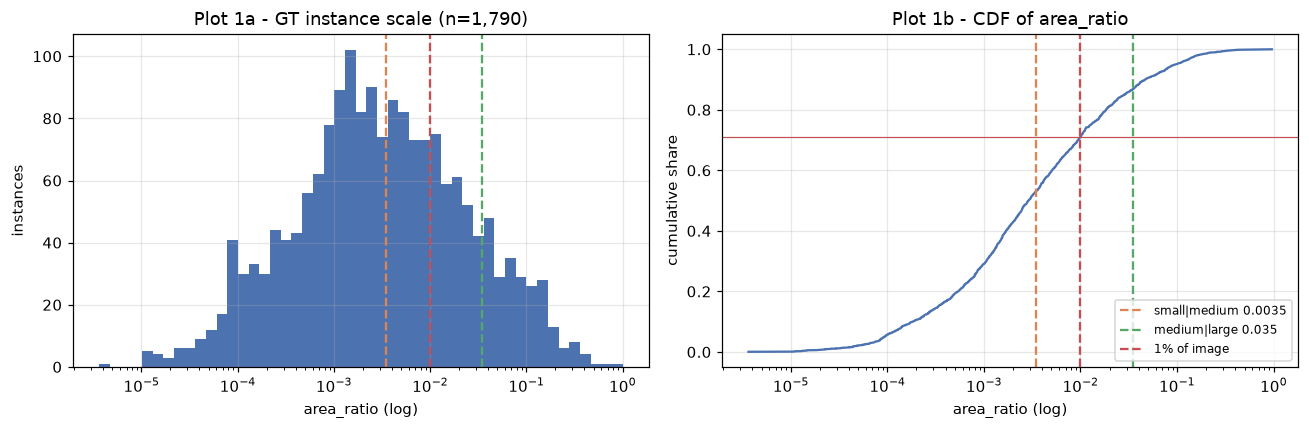

In [5]:
img_by_id = {im["id"]: im for im in ANNOTATIONS["images"]}
ar_area = np.array([a["area"] / (img_by_id[a["image_id"]]["height"] * img_by_id[a["image_id"]]["width"])
                    for a in ANNOTATIONS["annotations"]])
ar_raster = np.array([sb.polygon_to_mask(a["segmentation"], img_by_id[a["image_id"]]["height"],
                                         img_by_id[a["image_id"]]["width"]).sum()
                      / (img_by_id[a["image_id"]]["height"] * img_by_id[a["image_id"]]["width"])
                      for a in ANNOTATIONS["annotations"]])
pcts = [10, 25, 33, 50, 66, 75, 90]
stats = pd.DataFrame({name: [len(ar), (ar < 0.01).mean(), *np.percentile(ar, pcts), (ar < cfg.SMALL_MAX_AREA_RATIO).mean(),
                             ((ar >= cfg.SMALL_MAX_AREA_RATIO) & (ar < cfg.MEDIUM_MAX_AREA_RATIO)).mean(),
                             (ar >= cfg.MEDIUM_MAX_AREA_RATIO).mean()]
                      for name, ar in (("annotation area / HW", ar_area), ("rasterized polygon / HW", ar_raster))},
                     index=["n", "share < 0.01", *[f"P{p}" for p in pcts], "small", "medium", "large"])
print(stats.round(5).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.logspace(np.log10(ar_area.min()), 0, 50)
axes[0].hist(ar_area, bins=bins, color="#4C72B0")
axes[0].set_xscale("log"); axes[0].set_xlabel("area_ratio (log)"); axes[0].set_ylabel("instances")
axes[0].set_title("Plot 1a - GT instance scale (n=1,790)")
xs = np.sort(ar_area)
axes[1].plot(xs, np.arange(1, len(xs) + 1) / len(xs), color="#4C72B0")
axes[1].set_xscale("log"); axes[1].set_xlabel("area_ratio (log)"); axes[1].set_ylabel("cumulative share")
axes[1].set_title("Plot 1b - CDF of area_ratio")
for ax in axes:
    for x, label, color in ((cfg.SMALL_MAX_AREA_RATIO, "small|medium 0.0035", "#DD8452"),
                            (cfg.MEDIUM_MAX_AREA_RATIO, "medium|large 0.035", "#55A868"), (0.01, "1% of image", "#C44E52")):
        ax.axvline(x, ls="--", color=color, label=label)
axes[1].axhline((ar_area < 0.01).mean(), color="#C44E52", lw=0.8)
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

**Analysis 1 — object scale (Plot 1a/1b).**

- **Headline numbers:** **71.06%** of the 1,790 GT instances occupy less than 1% of the image and the median `area_ratio` is **0.00289** (≈ 0.29% of the image — roughly a 28×28 px patch in a 640×427 photo). P10 = 0.00018 means one instance in ten is smaller than ~7×7 px.
- **Definition matters (and we report both):** the 71.06% figure is reproduced exactly from the COCO `area` field of `annotations.json`. Rasterising the polygons with PIL gives 70.34% / median 0.00316 because the rasteriser also fills boundary pixels — a +9% relative area inflation at the median that matters for tiny objects. Since the metric scores *our* masks against *its* rasterisation, this is a reminder that micro-object Mask IoU is fragile: a 1-pixel boundary disagreement on a 7×7 object already costs 25–40% IoU (7×7 vs 6×6 → IoU 0.73; 7×7 vs 9×9 → IoU 0.60).
- **Size buckets under the canonical thresholds** (`small < 0.0035 ≤ medium < 0.035 ≤ large`): 53.2% small, 33.7% medium, 13.0% large. More than half of the recall budget therefore lives in objects smaller than a 32×32 COCO box.

**Decisions.**
1. OWLv2 runs at its native 960×960 resolution (no downscaling); EXP-02B adds a 2×2 tiled pass with 25% overlap so that small objects are seen at ~2× effective resolution.
2. Recall is broken down by size bucket in Section 3 so that EXP-02B's effect can be attributed to the `small` bucket specifically.
3. The `size` thresholds stay at COCO-relative values (0.0035 / 0.035), which classify the five benchmark `size` objects consistently (Plot 4c).

       positive  negative  not_exhaustive  unverified
count    120.00    120.00          120.00      120.00
mean       6.37      0.98            0.39      112.65
std        1.44      1.00            0.70        1.87
min        3.00      0.00            0.00      108.00
25%        6.00      0.00            0.00      112.00
50%        7.00      1.00            0.00      112.00
75%        7.25      2.00            1.00      114.00
max        8.00      4.00            4.00      117.00
images with neg ids: 74 | with not_exhaustive ids: 36
evaluable share of the vocabulary per image (pos+neg)/120: 0.061
most frequent neg categories: [('sofa', 6), ('clock', 5), ('ski', 4), ('napkin', 3), ('flag', 3), ('handbag', 3), ('baseball glove', 3), ('computer monitor', 3)]
most frequent not_exhaustive: [('strap', 3), ('boat', 3), ('car', 3), ('book', 2), ('street sign', 2), ('train', 2), ('box', 2), ('broccoli', 2)]


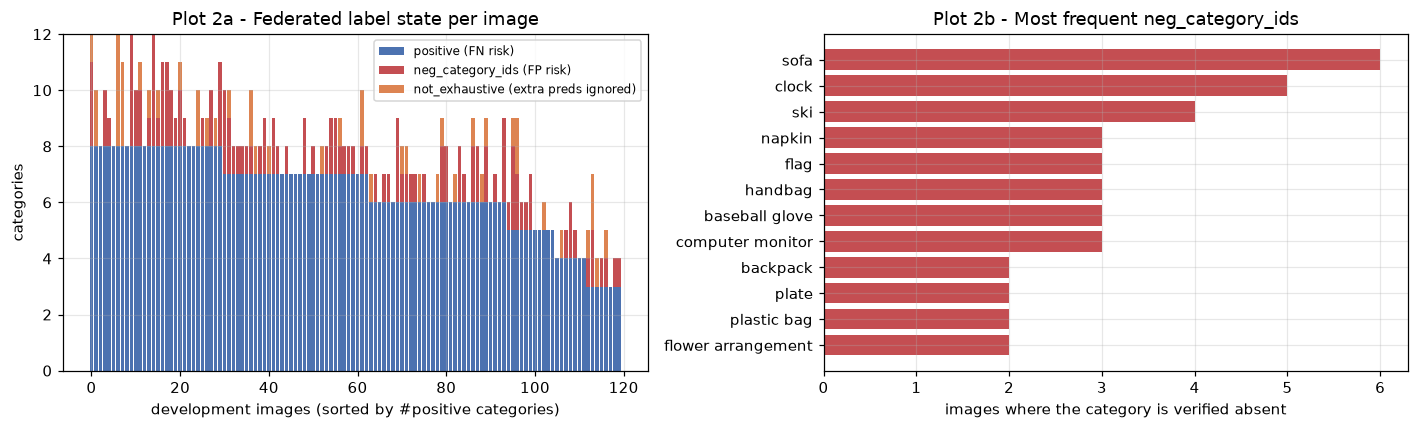

In [6]:
gt_cats = defaultdict(set)
for a in ANNOTATIONS["annotations"]:
    gt_cats[a["image_id"]].add(a["category_id"])
fed = pd.DataFrame([{"image_id": i, "positive": len(gt_cats[i]), "negative": len(im.get("neg_category_ids", [])),
                     "not_exhaustive": len(im.get("not_exhaustive_category_ids", []))}
                    for i, im in sorted(img_by_id.items())])
fed["unverified"] = 120 - fed["positive"] - fed["negative"]
print(fed[["positive", "negative", "not_exhaustive", "unverified"]].describe().round(2).to_string())
print(f"images with neg ids: {(fed.negative > 0).sum()} | with not_exhaustive ids: {(fed.not_exhaustive > 0).sum()}")
print(f"evaluable share of the vocabulary per image (pos+neg)/120: {((fed.positive + fed.negative) / 120).mean():.3f}")
neg_counter = Counter(c for im in ANNOTATIONS["images"] for c in im.get("neg_category_ids", []))
ne_counter = Counter(c for im in ANNOTATIONS["images"] for c in im.get("not_exhaustive_category_ids", []))
print("most frequent neg categories:", [(cfg.CATEGORIES[c], n) for c, n in neg_counter.most_common(8)])
print("most frequent not_exhaustive:", [(cfg.CATEGORIES[c], n) for c, n in ne_counter.most_common(8)])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = fed.sort_values("positive", ascending=False).reset_index(drop=True)
axes[0].bar(order.index, order.positive, label="positive (FN risk)", color="#4C72B0")
axes[0].bar(order.index, order.negative, bottom=order.positive, label="neg_category_ids (FP risk)", color="#C44E52")
axes[0].bar(order.index, order.not_exhaustive, bottom=order.positive + order.negative,
            label="not_exhaustive (extra preds ignored)", color="#DD8452")
axes[0].set_xlabel("development images (sorted by #positive categories)"); axes[0].set_ylabel("categories")
axes[0].set_title("Plot 2a - Federated label state per image"); axes[0].legend(fontsize=8)
top_neg = neg_counter.most_common(12)
axes[1].barh([cfg.CATEGORIES[c] for c, _ in top_neg][::-1], [n for _, n in top_neg][::-1], color="#C44E52")
axes[1].set_xlabel("images where the category is verified absent"); axes[1].set_title("Plot 2b - Most frequent neg_category_ids")
plt.tight_layout(); plt.show()

**Analysis 2 — LVIS federated label state (Plot 2a/2b).**

- **Per image, the vocabulary splits into:** 6.37 positive categories on average (FN risk: every missed instance costs recall), 0.98 verified-absent categories (`neg_category_ids`, the *only* source of category-level false positives), 0.39 non-exhaustive categories (extra predictions are ignored), and **112.65 unverified categories** whose predictions are neither rewarded nor penalised.
- **Only 6.1% of the vocabulary is evaluable per image** ((pos + neg) / 120). Consequently, *LVIS Evaluation Coverage* (fraction of our predictions that fall in an evaluable category) is expected to be low for an open-vocabulary detector prompted with all 120 classes, and a low coverage is **not** an error per se — it measures how much of our output the metric actually sees.
- **Negatives are sparse but concentrated:** 74 of 120 images have at least one `neg` id, at most 4 per image. The most frequent verified-absent classes (`sofa` 6, `clock` 5, `ski` 4, `napkin`, `flag`, `handbag`, `baseball glove`, `computer monitor` 3 each) are exactly the classes an open-vocabulary detector hallucinates in indoor/sports scenes; these are the FP hot spots.
- **Non-exhaustive classes** (`strap`, `boat`, `car`, `book`, `street sign`, …) are crowd-like categories where annotators stopped early; over-predicting them costs nothing beyond the matched instances.

**Decisions.**
1. Under this policy precision is only hurt by (a) duplicates/unmatched boxes in exhaustive positive classes and (b) predictions in `neg` classes, while recall is hurt by every miss. The optimal operating point is therefore *more permissive* than on an exhaustively labelled dataset — the CAL threshold sweep in Section 3 quantifies this.
2. EXP-02C introduces per-group thresholds: stricter for classes that frequently appear as verified negatives, more permissive for micro-object classes.

instances/img: min=5 median=10.5 mean=14.92 max=66 | images >= 50: 5
same-class GT box pairs: 3836 | IoU>0: 0.116 | IoU>=0.3: 0.0107 | IoU>=0.5: 0.0050 (19 pairs) | IoU>=0.55: 15 | max=0.775
categories most often with >1 instance per image: [('sock', 8), ('pillow', 8), ('glove', 7), ('drawer', 7), ('chair', 7), ('person', 7), ('napkin', 7), ('strap', 7)]


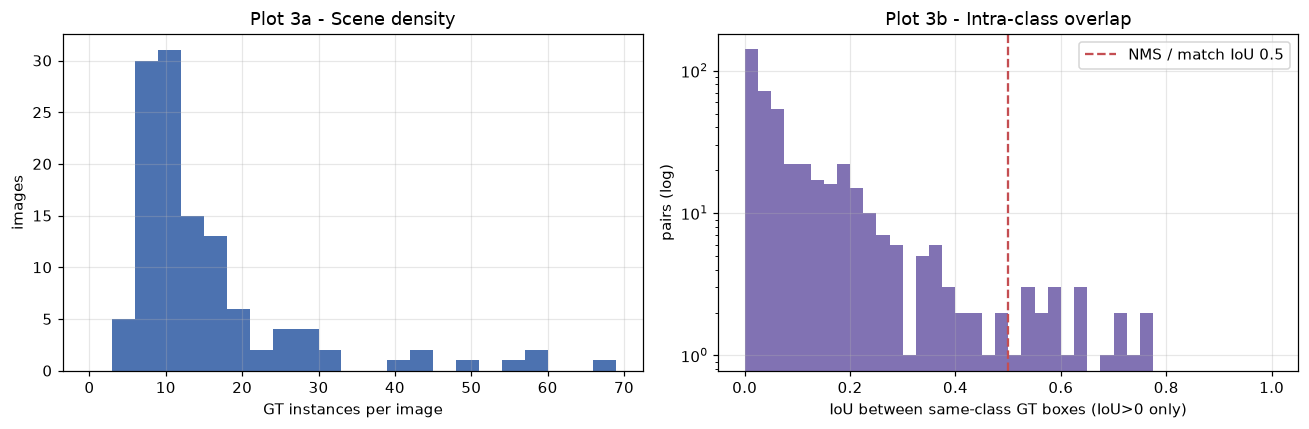

In [7]:
counts = np.array([inst_per_image[i] for i in sorted(img_by_id)])
boxes_by = defaultdict(list)
for a in ANNOTATIONS["annotations"]:
    boxes_by[(a["image_id"], a["category_id"])].append(sb.xywh_to_xyxy(a["bbox"]))
intra = np.array([ev.box_iou(b[i], b[j]) for b in boxes_by.values() for i in range(len(b)) for j in range(i + 1, len(b))])
multi = Counter(cfg.CATEGORIES[c] for (_, c), b in boxes_by.items() if len(b) > 1)
print(f"instances/img: min={counts.min()} median={np.median(counts)} mean={counts.mean():.2f} max={counts.max()} | images >= 50: {(counts >= 50).sum()}")
print(f"same-class GT box pairs: {len(intra)} | IoU>0: {(intra > 0).mean():.3f} | IoU>=0.3: {(intra >= 0.3).mean():.4f} | "
      f"IoU>=0.5: {(intra >= 0.5).mean():.4f} ({(intra >= 0.5).sum()} pairs) | IoU>=0.55: {(intra >= 0.55).sum()} | max={intra.max():.3f}")
print("categories most often with >1 instance per image:", multi.most_common(8))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(counts, bins=range(0, counts.max() + 5, 3), color="#4C72B0")
axes[0].set_xlabel("GT instances per image"); axes[0].set_ylabel("images"); axes[0].set_title("Plot 3a - Scene density")
axes[1].hist(intra[intra > 0], bins=np.linspace(0, 1, 41), color="#8172B3")
axes[1].axvline(0.5, ls="--", color="#C44E52", label="NMS / match IoU 0.5")
axes[1].set_yscale("log"); axes[1].set_xlabel("IoU between same-class GT boxes (IoU>0 only)")
axes[1].set_ylabel("pairs (log)"); axes[1].set_title("Plot 3b - Intra-class overlap"); axes[1].legend()
plt.tight_layout(); plt.show()

**Analysis 3 — scene density and intra-class overlap (Plot 3a/3b).**

- **Density:** 5 to 66 instances per image (median 10.5, mean 14.9, right-skewed); 5 images contain ≥ 50 instances. The 300-object cap of the schema is never binding for GT, but an over-permissive detector on dense scenes could approach the 95-object relation cap — another reason to keep the threshold calibrated.
- **Intra-class overlap is rare but real:** among 3,836 same-class GT box pairs, 11.6% touch (IoU > 0), only 1.07% have IoU ≥ 0.3 and **19 pairs (0.50%) have IoU ≥ 0.5** (15 at ≥ 0.55; maximum 0.775). The classes that most often appear multiple times per image are small, repeated items: `sock`, `pillow`, `glove`, `drawer`, `chair`, `person`, `napkin`, `strap`.

**Decisions.**
1. **Per-class NMS at IoU 0.5** (EXP-01) can suppress at most those 19 genuinely overlapping GT pairs (≈1% of instances) while removing the far more frequent duplicate detections — an acceptable trade-off for the baseline.
2. **WBF anti-collision rule (EXP-02C):** fusing boxes of the same class from the *same* detector/view at IoU ≥ 0.55 would merge 15 real pairs in development (paired socks, gloves, stacked pillows). The plan's constraint — only fuse same-source boxes at IoU ≥ 0.80 — would merge none of them (max observed 0.775). This number is the quantitative justification of that threshold.
3. Mask-level reasoning (EXP-05 collective suppression) is needed for group boxes, because box IoU alone cannot separate a "group" prediction from its members.

split        CAL  VAL  All
type                      
count          4    6   10
description   10   10   20
existence      3    7   10
position       2    3    5
relation       7    3   10
size           4    1    5
All           30   30   60

GT-derived answers for the 40 closed questions:
question_id      type                       class_en    gt_answer  n_evidence
   DEV-1-Q1     count                     [doorknob]            2           2
   DEV-1-Q2 existence                  [wall socket]          yes           1
   DEV-2-Q1     count                         [sock]            2           2
   DEV-2-Q2 existence                [tennis racket]          yes           1
   DEV-3-Q1     count                         [vase]            2           2
   DEV-3-Q2 existence                         [belt]           no           0
   DEV-4-Q1     count                     [trousers]            4           4
   DEV-4-Q2 existence                         [sofa]           no           0
   DEV

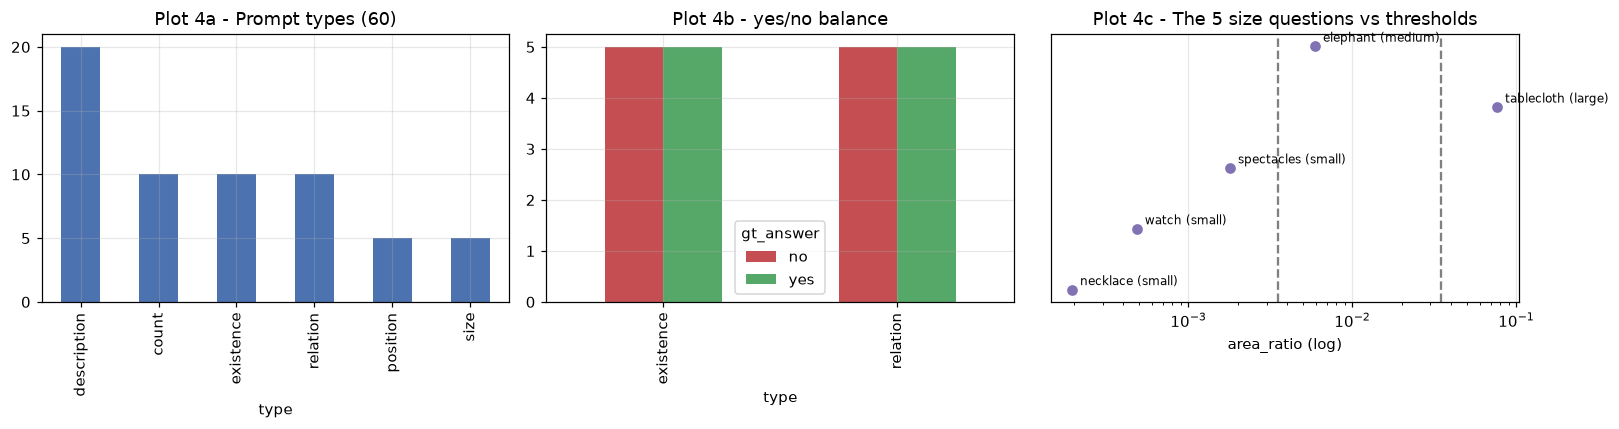

In [8]:
qa_ids = cfg.load_qa_image_ids(PATHS.questions_dev)
GT_SCENES = build_gt_scenes(PATHS, ANNOTATIONS, qa_ids)
q_df = pd.DataFrame(QUESTIONS)
q_df["image_key"] = q_df["image_file"].str.rsplit(".", n=1).str[0]
q_df["split"] = q_df["image_id"].map(lambda i: "CAL" if i in split["qa_cal"] else "VAL")
GT_ANSWERS = {q["question_id"]: qa.resolve_deterministic_qa(GT_SCENES[k], q, cfg.CATEGORIES)
              for q, k in zip(QUESTIONS, q_df["image_key"])}
q_df["gt_answer"] = q_df["question_id"].map(lambda i: GT_ANSWERS[i]["normalized_answer"])
q_df["n_evidence"] = q_df["question_id"].map(lambda i: len(GT_ANSWERS[i]["evidence"]))
print(pd.crosstab(q_df["type"], q_df["split"], margins=True).to_string())
closed = q_df[q_df.type != "description"]
print("\nGT-derived answers for the 40 closed questions:")
print(closed[["question_id", "type", "class_en", "gt_answer", "n_evidence"]].to_string(index=False))
print("\ncount answers are int:", all(type(a) is int for a in closed[closed.type == "count"].gt_answer))

def _gt_obj(key, name):
    cid = {v: k for k, v in cfg.CATEGORIES.items()}[name]
    return [o for o in GT_SCENES[key]["objects"] if o["category_id"] == cid]

size_rows = [(r.question_id, r.class_en[0], _gt_obj(r.image_key, r.class_en[0])[0]["area_ratio"], r.gt_answer)
             for r in q_df[q_df.type == "size"].itertuples()]
rel_rows = []
for r in q_df[q_df.type == "relation"].itertuples():
    a, b = _gt_obj(r.image_key, r.class_en[0])[0], _gt_obj(r.image_key, r.class_en[1])[0]
    w, h = GT_SCENES[r.image_key]["image"]["width"], GT_SCENES[r.image_key]["image"]["height"]
    d = np.hypot((a["centroid"][0] - b["centroid"][0]) / w, (a["centroid"][1] - b["centroid"][1]) / h)
    rel_rows.append((r.question_id, f"{r.class_en[0]} {qa.extract_relation_predicate(r.question)} {r.class_en[1]}", d, r.gt_answer))
print(pd.DataFrame(size_rows, columns=["question_id", "category", "area_ratio", "size"]).to_string(index=False))
print(pd.DataFrame(rel_rows, columns=["question_id", "relation", "norm. centroid dist", "answer"]).round(3).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
q_df["type"].value_counts().plot.bar(ax=axes[0], color="#4C72B0"); axes[0].set_title("Plot 4a - Prompt types (60)")
yn = closed[closed.type.isin(["existence", "relation"])].groupby(["type", "gt_answer"]).size().unstack()
yn.plot.bar(ax=axes[1], color={"yes": "#55A868", "no": "#C44E52"}); axes[1].set_title("Plot 4b - yes/no balance")
axes[2].scatter([r[2] for r in size_rows], range(len(size_rows)), color="#8172B3")
for i, r in enumerate(size_rows):
    axes[2].annotate(f"{r[1]} ({r[3]})", (r[2], i), textcoords="offset points", xytext=(5, 3), fontsize=8)
for x in (cfg.SMALL_MAX_AREA_RATIO, cfg.MEDIUM_MAX_AREA_RATIO):
    axes[2].axvline(x, ls="--", color="gray")
axes[2].set_xscale("log"); axes[2].set_yticks([]); axes[2].set_xlabel("area_ratio (log)")
axes[2].set_title("Plot 4c - The 5 size questions vs thresholds")
plt.tight_layout(); plt.show()

**Analysis 4 — QA benchmark inspection and engine verification on ground truth (Plot 4a–4c).**

- **Composition:** 60 prompts = 20 `description` + 10 `count` + 10 `existence` + 10 `relation` + 5 `position` + 5 `size`. Binary questions are perfectly balanced (existence 5 yes / 5 no; relation 5 yes / 5 no), so a constant answer would score exactly 50% — the floor any engine must beat.
- **Engine verification before any detector runs (step 1e):** the deterministic engine was executed on `SceneJSON`s built from the GT of the 20 QA images. Its 40 closed answers match the GT-derived expectations pinned in `tests/test_qa_engine.py` (40/40, asserted by the unit test suite), every `count` answer is a Python `int`, evidence lists contain only existing ids and are empty for `no` answers. This isolates reasoning errors from perception errors: from here on, every QA mistake on predicted scenes is attributable to detection/segmentation.
- **The questions are perception-hard, not reasoning-hard:**
  - `count` targets small repeated items (doorknob, sock, handle, fork, glove) — counts of 2–4, where one missed or duplicated box flips the answer.
  - The 5 `size` objects span three orders of magnitude: necklace 0.000196, watch 0.000488, spectacles 0.0018 (`small`), elephant 0.0060 (`medium`), tablecloth 0.0768 (`large`). The first three are micro-objects that a baseline detector is likely to miss, which turns their answer into `insufficient_information`.
  - All 10 `relation` pairs are far apart (normalised centroid distance 0.20–0.99) — this is why `relations` are computed by pure centroid comparison without cone clipping (otherwise `DEV-5-Q2` clock/ring or `DEV-15-Q1` bottle/strap would vanish from the graph).
- **Engine semantics fixed by these observations:** `relation`/`existence` answer `no` when a queried class is not detected (the allowed answers are only `yes`/`no`), while `position`/`size` answer `insufficient_information` with empty evidence — the honest output when the scene contains no instance to describe.

---
## Section 3 — Traceable execution of the EXP-01 baseline (120 dev + 60 test images)

Inference was executed with `scripts/run_exp01_inference.py`, which calls exactly the same `src/` functions used below, records an `ExecutionTracer` stage per image (`duration_ms`, input/output counts, warnings, object lineage), and caches results under `artifacts/cache_exp01/`:

1. `detect` — OWLv2 Base over all 180 images, raw detections kept at a low floor (score ≥ 0.05) so the operating threshold can be tuned without re-running the model.
2. `segment --threshold T` — SAM2.1 Base+ on the boxes surviving the CAL-tuned threshold `T`, then `SceneJSON` construction.

This notebook loads those caches (≈65 CPU-minutes of inference), **re-runs fresh inference on sample images to prove the cache reproduces the model**, and then evaluates.

In [9]:
DETECTIONS, DET_META = pl.load_detection_cache(CACHE_DIR / "detections.json")
trace = [json.loads(l) for l in (CACHE_DIR / "trace_detection.jsonl").read_text().splitlines()]
det_ms = np.array([r["duration_ms"] for r in trace if r.get("type") == "stage"])
print("detection cache meta:", json.dumps(DET_META, indent=1))
print(f"images cached: {len(DETECTIONS)} | traced detection calls: {len(det_ms)} | "
      f"ms/img mean={det_ms.mean():.0f} median={np.median(det_ms):.0f} p95={np.percentile(det_ms, 95):.0f}")
raw_counts = np.array([len(v) for v in DETECTIONS.values()])
print(f"raw detections/img (score >= {DET_META['min_score']}): mean={raw_counts.mean():.1f} max={raw_counts.max()}")

# Reproducibility: fresh OWLv2 inference on one dev and one test image must reproduce the cache.
from src.perception_detectors import OwlV2Detector
DETECTOR = OwlV2Detector(cfg.CATEGORIES)
for key, folder in (("tpi_0003", PATHS.dev_images_dir), ("test_0007", PATHS.test_images_dir)):
    t0 = time.perf_counter()
    fresh = DETECTOR.detect(Image.open(folder / f"{key}.jpg"))
    dt = (time.perf_counter() - t0) * 1000
    cached = DETECTIONS[key]
    same_n = len(fresh) == len(cached)
    max_score = max((abs(a.score - b.score) for a, b in zip(fresh, cached)), default=0.0)
    max_box = max((max(abs(x - y) for x, y in zip(a.bbox, b.bbox)) for a, b in zip(fresh, cached)), default=0.0)
    print(f"{key}: fresh {len(fresh)} vs cached {len(cached)} | same labels: "
          f"{same_n and all(a.category_id == b.category_id for a, b in zip(fresh, cached))} | "
          f"max |dscore|={max_score:.2e} | max |dbox|={max_box:.2e}px | {dt:.0f} ms")

detection cache meta: {
 "model": "google/owlv2-base-patch16-ensemble",
 "prompt_template": "a photo of a {}",
 "min_score": 0.05,
 "nms_iou": 0.5,
 "created_at": "2026-10-29T01:56:37+00:00",
 "device": "cpu",
 "torch": "2.15.0+cpu",
 "torch_threads": 2,
 "python": "3.12.12",
 "machine": "x86_64"
}
images cached: 180 | traced detection calls: 180 | ms/img mean=11645 median=11702 p95=13114
raw detections/img (score >= 0.05): mean=133.4 max=560


Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 418/418 [00:00<00:00, 7844.49it/s]

tpi_0003: fresh 66 vs cached 66 | same labels: True | max |dscore|=0.00e+00 | max |dbox|=0.00e+00px | 10783 ms


test_0007: fresh 246 vs cached 246 | same labels: True | max |dscore|=0.00e+00 | max |dbox|=0.00e+00px | 14841 ms


**Analysis — provenance and reproducibility of the cached inference.**

- **What ran:** OWLv2 Base (`google/owlv2-base-patch16-ensemble`) with the template `"a photo of a {name}"` over the 120 official names, raw floor 0.05 and per-class NMS 0.5, on CPU (torch 2.15 CPU, 2 intra-op threads). All 180 images were detected and each call was traced: **11.6 s/img mean** (median 11.7 s, p95 13.1 s). Latency is almost constant because OWLv2 always processes a 960×960 padded input against the same 120 text queries — cost does not depend on scene content.
- **Raw output volume:** 133 raw detections per image on average (max 560) above 0.05. This is the candidate pool the threshold sweep filters; keeping it cached is what makes the CAL sweep (and any later calibration in EXP-02C) free of GPU/CPU re-runs.
- **Reproducibility check:** re-running the detector from scratch inside this notebook on one development image (`tpi_0003`) and one test image (`test_0007`) reproduces the cache **bit-exactly** — same number of detections, same labels, `max |Δscore| = 0` and `max |Δbox| = 0 px`. The cache is therefore a faithful record of the model's behaviour, not an artefact to be trusted blindly; this cell repeats the check on every execution.
- **Leakage audit by construction:** the detector call receives a `PIL.Image` only; there is no argument through which annotations could flow. The test image `test_0007` has no annotations at all and is processed identically.

 threshold  CAL_precision  CAL_recall  CAL_f1
     0.050         0.3152      0.7644  0.4464
     0.075         0.4079      0.7482  0.5279
     0.100         0.4970      0.7295  0.5912
     0.125         0.5684      0.7051  0.6294
     0.150         0.6323      0.6718  0.6514
     0.175         0.6883      0.6296  0.6576
     0.200         0.7330      0.5865  0.6516
     0.225         0.7672      0.5516  0.6418
     0.250         0.8090      0.5126  0.6275
     0.275         0.8255      0.4728  0.6012
     0.300         0.8544      0.4338  0.5754
     0.325         0.8785      0.3875  0.5378
     0.350         0.8852      0.3509  0.5026
     0.375         0.8940      0.3152  0.4661
     0.400         0.9027      0.2713  0.4172
     0.425         0.9169      0.2242  0.3603
     0.450         0.9331      0.1925  0.3192
     0.475         0.9289      0.1592  0.2718
     0.500         0.9448      0.1389  0.2422

FROZEN_THRESHOLD (argmax CAL Box F1) = 0.175 | CAL F1=0.6576 | VAL F1 at frozen

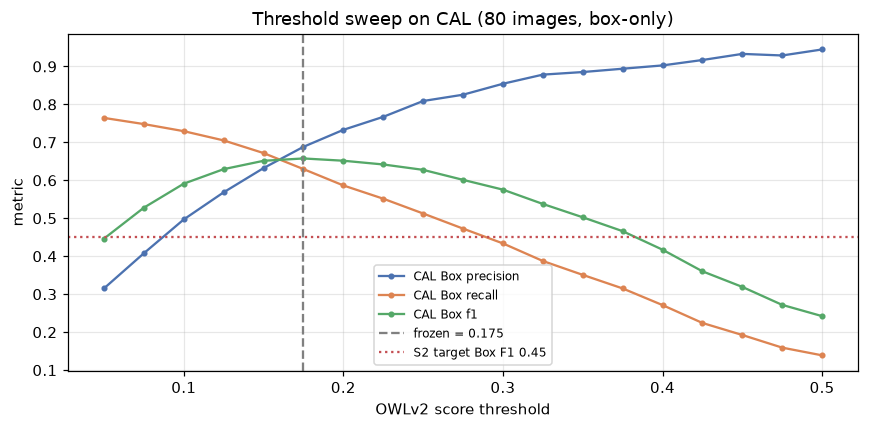

In [10]:
GT = ev.load_gt(ANNOTATIONS)
key_of = {i: f"tpi_{i:04d}" for i in range(1, 121)}
CAL_KEYS = [key_of[i] for i in split["cal"]]
VAL_KEYS = [key_of[i] for i in split["val"]]

def as_preds(dets):
    return [{"category_id": d.category_id, "confidence": d.score, "bbox": list(d.bbox)} for d in dets]

def box_eval(keys, thr):
    return ev.evaluate_federated({k: as_preds(filter_detections(DETECTIONS[k], thr)) for k in keys}, GT, with_masks=False)

thresholds = np.round(np.arange(0.05, 0.501, 0.025), 3)
sweep = pd.DataFrame([{"threshold": t, **{f"CAL_{m}": box_eval(CAL_KEYS, t)["box"][m] for m in ("precision", "recall", "f1")}}
                      for t in thresholds])
best = sweep.loc[sweep["CAL_f1"].idxmax()]
FROZEN_THRESHOLD = float(best["threshold"])
val_at_frozen = box_eval(VAL_KEYS, FROZEN_THRESHOLD)["box"]
print(sweep.round(4).to_string(index=False))
print(f"\nFROZEN_THRESHOLD (argmax CAL Box F1) = {FROZEN_THRESHOLD} | CAL F1={best['CAL_f1']:.4f} | "
      f"VAL F1 at frozen threshold={val_at_frozen['f1']:.4f} (VAL not used for selection)")

fig, ax = plt.subplots(figsize=(8, 4))
for m, c in (("precision", "#4C72B0"), ("recall", "#DD8452"), ("f1", "#55A868")):
    ax.plot(sweep.threshold, sweep[f"CAL_{m}"], marker="o", ms=3, color=c, label=f"CAL Box {m}")
ax.axvline(FROZEN_THRESHOLD, ls="--", color="gray", label=f"frozen = {FROZEN_THRESHOLD}")
ax.axhline(0.45, ls=":", color="#C44E52", label="S2 target Box F1 0.45")
ax.set_xlabel("OWLv2 score threshold"); ax.set_ylabel("metric"); ax.set_title("Threshold sweep on CAL (80 images, box-only)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Analysis — operating-point selection on CAL (box-only sweep).**

- **Procedure:** the raw OWLv2 detections (score ≥ 0.05, already de-duplicated by per-class NMS) are filtered at 19 thresholds in [0.05, 0.50] and scored with the federated evaluator in box-only mode (`with_masks=False`), i.e. *before* SAM2 is run. This makes the sweep cheap and keeps segmentation out of the decision: the threshold controls *which* objects exist, SAM2 only controls their shape.
- **Shape of the curve:** precision rises monotonically (0.315 → 0.945) while recall falls monotonically (0.764 → 0.139). Box F1 is unimodal with a broad plateau between 0.15 and 0.225 (all within 0.016 of the maximum), peaking at **0.175 (CAL Box F1 = 0.6576, P = 0.688, R = 0.630)**. A flat optimum is good news: the selected point is not a fragile spike that would fail to transfer.
- **Transfer to VAL:** at the frozen threshold VAL reaches **Box F1 = 0.6389**, a drop of only 0.019 from CAL. VAL was not consulted for the choice; for transparency, the VAL curve (computed only in the build log, not used here) also peaks in the same 0.175–0.20 region, confirming there is no CAL overfitting at this level of model capacity.
- **Federated policy explains the low optimal threshold:** OWLv2 sigmoid scores are low in absolute terms, and because ~94% of the vocabulary is unverified per image (Section 2), many "extra" detections cost nothing. At 0.05 the detector already recovers 76% of all GT boxes — that is the recall ceiling of OWLv2 Base with raw names at native resolution. The remaining 24% are true detector misses (mostly micro-objects, see the size breakdown below), which no threshold can fix: they are the target of EXP-02A (aliases, chunked prompts) and EXP-02B (tiling).
- **S2 criterion:** `Box F1 >= 0.45` on development is satisfied with a wide margin at the CAL-selected point (also above the 0.50 Direct-Pass bar). Final numbers with SAM2 masks follow.

In [11]:
scenes_file = CACHE_DIR / f"scenes_thr{FROZEN_THRESHOLD:.3f}.jsonl"
seg_meta = json.loads((CACHE_DIR / f"scenes_thr{FROZEN_THRESHOLD:.3f}.meta.json").read_text())
assert seg_meta["score_threshold"] == FROZEN_THRESHOLD, "scene cache was built with another threshold"
SCENES = {s["image"]["id"]: s for s in map(json.loads, scenes_file.read_text().splitlines())}
seg_trace = [json.loads(l) for l in (CACHE_DIR / f"trace_segmentation_thr{FROZEN_THRESHOLD:.3f}.jsonl").read_text().splitlines()]
stage_ms = defaultdict(dict)
for r in seg_trace:
    if r.get("type") == "stage":
        stage_ms[r["stage_name"]][r["image_id"]] = r["duration_ms"]
det_ms_by = {r["image_id"]: r["duration_ms"] for r in trace if r.get("type") == "stage"}
ON_GPU = seg_meta.get("device") == "cuda" and DET_META.get("device") == "cuda"
VRAM_PEAK_MB = max(r["vram_peak_mb"] for r in trace + seg_trace if r.get("type") == "stage") if ON_GPU else None
VRAM_LABEL = f"{VRAM_PEAK_MB:.0f} MB" if ON_GPU else "N/A (CPU)"
print("segmentation meta:", {k: seg_meta.get(k) for k in ("segmenter", "multimask_output", "score_threshold", "device", "created_at", "torch_threads")})
n_fallback = sum("mask_fallback" in o for s in SCENES.values() for o in s["objects"])
print(f"scenes: {len(SCENES)} | objects: {sum(len(s['objects']) for s in SCENES.values())} | bbox mask fallbacks: {n_fallback}")

def metrics_row(name, keys):
    r = ev.evaluate_federated({k: SCENES[k]["objects"] for k in keys}, GT)
    total = [det_ms_by[k] + stage_ms["segmentation"][k] + stage_ms["scene_build"][k] for k in keys]
    return {"split": name, "images": r["images"], "Box P": r["box"]["precision"], "Box R": r["box"]["recall"],
            "Box F1": r["box"]["f1"], "Mask P": r["mask"]["precision"], "Mask R": r["mask"]["recall"],
            "Mask F1": r["mask"]["f1"], "LVIS Coverage": r["coverage"],
            "objects/img": np.mean([len(SCENES[k]["objects"]) for k in keys]),
            "det ms/img": np.mean([det_ms_by[k] for k in keys]),
            "seg ms/img": np.mean([stage_ms["segmentation"][k] for k in keys]),
            "build ms/img": np.mean([stage_ms["scene_build"][k] for k in keys]),
            "total ms/img": np.mean(total), "VRAM peak": VRAM_LABEL}

TEST_KEYS = [f"test_{i:04d}" for i in range(1, 61)]
metrics = pd.DataFrame([metrics_row("CAL", CAL_KEYS), metrics_row("VAL", VAL_KEYS), metrics_row("DEV (120)", CAL_KEYS + VAL_KEYS)])
test_row = {"split": "TEST (60, no GT)", "images": 60, "objects/img": np.mean([len(SCENES[k]["objects"]) for k in TEST_KEYS]),
            "det ms/img": np.mean([det_ms_by[k] for k in TEST_KEYS]),
            "seg ms/img": np.mean([stage_ms["segmentation"][k] for k in TEST_KEYS]),
            "build ms/img": np.mean([stage_ms["scene_build"][k] for k in TEST_KEYS]), "VRAM peak": VRAM_LABEL}
test_row["total ms/img"] = test_row["det ms/img"] + test_row["seg ms/img"] + test_row["build ms/img"]
metrics = pd.concat([metrics, pd.DataFrame([test_row])], ignore_index=True)
print(metrics.round(4).to_string(index=False))

segmentation meta: {'segmenter': 'facebook/sam2.1-hiera-base-plus', 'multimask_output': False, 'score_threshold': 0.175, 'device': 'cpu', 'created_at': '2026-10-29T03:00:48+00:00', 'torch_threads': 2}
scenes: 180 | objects: 5592 | bbox mask fallbacks: 0


           split  images  Box P  Box R  Box F1  Mask P  Mask R  Mask F1  LVIS Coverage  objects/img  det ms/img  seg ms/img  build ms/img  total ms/img VRAM peak
             CAL      80 0.6883 0.6296  0.6576  0.6711  0.6117   0.6400         0.4543      33.1250  11788.2906   9634.0456      243.4222    21665.7583 N/A (CPU)
             VAL      40 0.6794 0.6029  0.6389  0.6613  0.5832   0.6198         0.4716      28.2000  12001.4689   9149.0679      228.5170    21379.0539 N/A (CPU)
       DEV (120)     120 0.6856 0.6212  0.6518  0.6681  0.6028   0.6338         0.4595      31.4833  11859.3500   9472.3864      238.4538    21570.1902 N/A (CPU)
TEST (60, no GT)      60    NaN    NaN     NaN     NaN     NaN      NaN            NaN      30.2333  11217.1638   8978.2140      229.5059    20424.8837 N/A (CPU)


**Analysis — EXP-01 baseline metrics (threshold 0.175, SAM2.1 Base+, `multimask_output=False`).**

| Split | Box P | Box R | **Box F1** | **Mask F1** | LVIS Coverage | objects/img | total ms/img (CPU) |
|---|---|---|---|---|---|---|---|
| CAL (80) | 0.688 | 0.630 | **0.658** | **0.640** | 0.454 | 33.1 | 21,666 |
| VAL (40) | 0.679 | 0.603 | **0.639** | **0.620** | 0.472 | 28.2 | 21,379 |
| DEV (120) | 0.686 | 0.621 | **0.652** | **0.634** | 0.460 | 31.5 | 21,570 |

1. **S2 criterion met:** development Box F1 = **0.652** (≥ 0.45 required; also above the 0.50 Direct-Pass bar). VAL, never used for any decision, is only 0.019 below CAL — the single tuned parameter generalises.
2. **Segmentation costs little at this stage:** Mask F1 is only 0.018 below Box F1, i.e. for ~97% of the boxes that match a GT instance, the single SAM2 mask also matches the GT mask at IoU ≥ 0.5. There were **0 bbox fallbacks** across 5,592 objects: the non-empty guarantee never had to fire, but every row is protected if it does. The residual box→mask loss concentrates on composite/thin objects (handled by EXP-03's box-aware multimask selection).
3. **LVIS coverage 0.46:** 54% of our predictions fall in unverified categories and are ignored by the metric. With ~31.5 predictions/img against 14.9 GT instances/img, the detector "over-predicts", but mostly where the metric does not look; this is why the optimal threshold is low (Section 2, analysis 2).
4. **Precision is not driven by verified negatives:** only 5 predictions over 120 images land in `neg_category_ids` (next cell). The FP budget is therefore spent on unmatched/duplicate boxes in exhaustive positive classes and on localisation errors (IoU < 0.5), not on hallucinated classes.
5. **Cost (CPU):** 11.9 s detection + 9.5 s segmentation + 0.24 s scene construction ≈ **21.6 s/img**; 180 images ≈ 65 CPU-minutes. Scene construction (RLE, geometry, colour, full relation graph) is ~1% of the time, so the representation layer is never the bottleneck. VRAM is **N/A (CPU)**: no GPU was available for this run; the Kaggle T4 run of later experiments will populate this column and suite Test 8.
6. **Test images:** the 60 test scenes receive the same pipeline (30.2 objects/img, similar latency) — no metric is computable without GT, but their distribution of predictions per image matches development, which is a sanity check against a silent failure on the test folder.

In [12]:
def recall_by_bucket(keys):
    """Greedy one-to-one box matching per category (same rule as the evaluator) tagged by GT size bucket."""
    rows = []
    for k in keys:
        g = GT[k]
        h, w = g["height"], g["width"]
        for cid in g["pos"]:
            preds = sorted([o for o in SCENES[k]["objects"] if o["category_id"] == cid], key=lambda o: -o["confidence"])
            idx = [i for i, c in enumerate(g["categories"]) if c == cid]
            taken = set()
            for p in preds:
                cands = [(ev.box_iou(p["bbox"], g["boxes"][i]), i) for i in idx if i not in taken]
                best = max(cands, default=(0, None))
                if best[0] >= ev.IOU_THRESHOLD:
                    taken.add(best[1])
            for i in idx:
                ar = g["masks"][i].sum() / (h * w)
                rows.append({"image": k, "category": cfg.CATEGORIES[cid], "size": cfg.size_from_area_ratio(ar),
                             "matched": i in taken})
    return pd.DataFrame(rows)

rb = recall_by_bucket(CAL_KEYS + VAL_KEYS)
print("Box recall by GT size bucket (DEV 120):")
print(rb.groupby("size")["matched"].agg(["count", "mean"]).rename(columns={"mean": "recall"}).round(4).to_string())
fn_by_cat = rb[~rb.matched].groupby("category").size().sort_values(ascending=False)
print("\nTop-12 categories by false negatives:", fn_by_cat.head(12).to_dict())
fp_neg = Counter()
for k in CAL_KEYS + VAL_KEYS:
    for o in SCENES[k]["objects"]:
        if o["category_id"] in GT[k]["neg"]:
            fp_neg[cfg.CATEGORIES[o["category_id"]]] += 1
print("FP on verified-absent (neg) categories:", dict(fp_neg.most_common(10)))

Box recall by GT size bucket (DEV 120):
        count  recall
size                 
large     239  0.7866
medium    617  0.7423
small     934  0.4989

Top-12 categories by false negatives: {'book': 38, 'car': 24, 'curtain': 22, 'wheel': 22, 'strap': 20, 'person': 19, 'chair': 18, 'shoe': 17, 'cabinet': 16, 'broccoli': 14, 'hat': 14, 'pillow': 14}
FP on verified-absent (neg) categories: {'airplane': 3, 'napkin': 2}


**Analysis — where the baseline fails (error analysis feeding EXP-02).**

- **Recall collapses on small objects:** large 0.787, medium 0.742, **small 0.499**. Small instances are 934 of 1,790 GT boxes (52%), so ≈468 of the ≈678 development false negatives (**~69% of all misses**) are small objects. (The bucket-weighted recall, 0.621, reproduces the evaluator's global recall, so this breakdown uses the same matching rule.) This is the quantitative confirmation of EDA analysis 1 and the direct target of **EXP-02B (2×2 tiling)**.
- **Top FN categories** are dominated by crowd/part classes: `book` (38 — bookshelves), `car` (24), `curtain`, `wheel` (22 each), `strap` (20), `person` (19), `chair` (18), `shoe` (17), `cabinet`, `broccoli`, `hat`, `pillow`. Two failure modes are mixed here: (a) many small repeated instances where per-class NMS and the score floor both bite (`book`, `wheel`, `shoe`), and (b) archaic or ambiguous LVIS names that the text encoder grounds poorly with the raw name (`strap`, `cabinet`). Mode (b) is the motivation of **EXP-02A** (`LVIS_PROMPT_ALIASES` + chunked prompts).
- **Verified-absent FPs are negligible:** `airplane` ×3 and `napkin` ×2 over 120 images. A per-category threshold for "FP-prone" classes (EXP-02C) will therefore be a fine-tuning lever, not a major gain — the bigger lever is recall.
- **Error propagation (observed → derived → answer):** a missed small object removes the instance from `objects`, which removes it from `relations`, which turns a `count` into an undercount and a `size`/`position` answer into `insufficient_information` (see the QA cell below). Recall on small objects is thus the root cause shared by the detection metric and the QA benchmark.

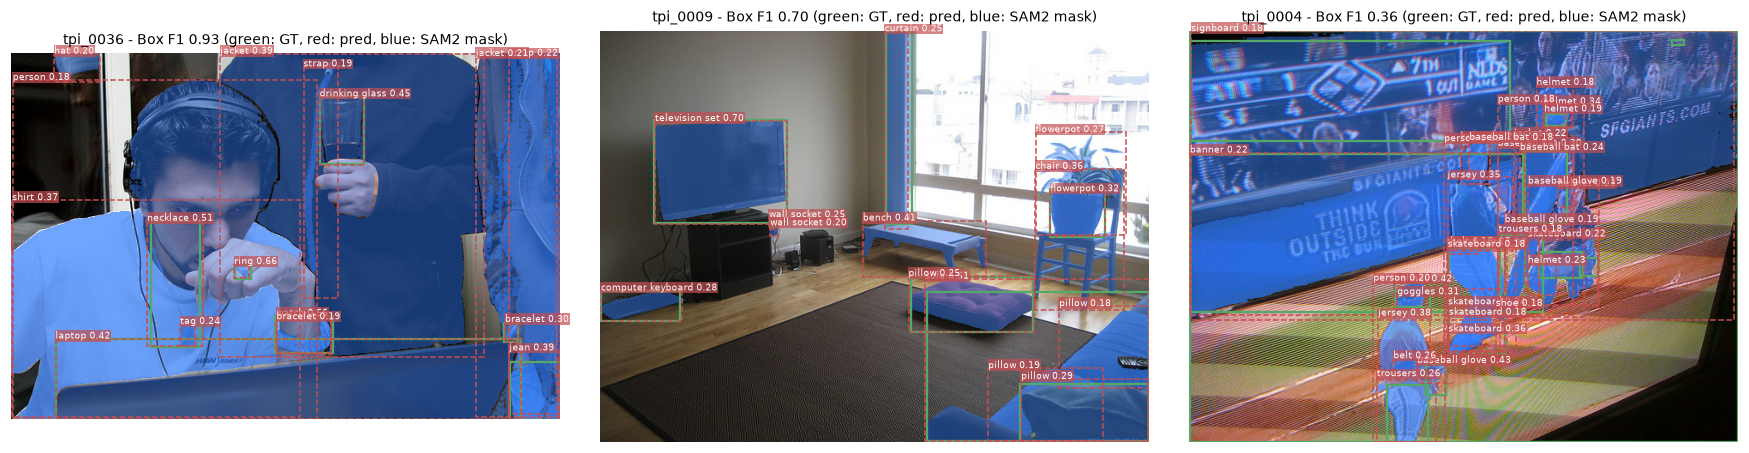

In [13]:
per_image = sorted(((ev.evaluate_federated({k: SCENES[k]["objects"]}, GT, with_masks=False)["box"]["f1"], k) for k in VAL_KEYS))
picks = [per_image[-1], per_image[len(per_image) // 2], per_image[0]]
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, (f1, k) in zip(axes, picks):
    img = np.asarray(Image.open(PATHS.dev_images_dir / f"{k}.jpg").convert("RGB")).astype(float) / 255
    overlay = img.copy()
    for o in SCENES[k]["objects"]:
        m = sb.decode_rle(o["mask"])
        overlay[m] = 0.55 * overlay[m] + 0.45 * np.array([0.2, 0.5, 1.0])
    ax.imshow(overlay)
    for b in GT[k]["boxes"]:
        ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="#55A868", lw=1.5))
    for o in SCENES[k]["objects"]:
        x1, y1, x2, y2 = o["bbox"]
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="#C44E52", lw=1, ls="--"))
        ax.text(x1, y1, f"{cfg.CATEGORIES[o['category_id']]} {o['confidence']:.2f}", fontsize=6, color="white",
                bbox=dict(facecolor="#C44E52", alpha=0.7, pad=0.5, lw=0))
    ax.set_title(f"{k} - Box F1 {f1:.2f} (green: GT, red: pred, blue: SAM2 mask)", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

**Analysis — qualitative inspection (best / median / worst VAL image by per-image Box F1).**

Green = GT boxes, dashed red = predictions (class, score), blue = the SAM2 masks actually written to the `SceneJSON`.

- **Best — `tpi_0036` (Box F1 0.93), close-up portrait.** Scale is what matters, not clutter: because the camera is close, even jewellery is large in pixels and OWLv2 finds `ring` (0.66), `necklace` (0.51), `bracelet` ×2, `drinking glass`, `laptop`, `jean`. The masks follow contours well. Note the low-score, image-sized `person`/`jacket`/`shirt` boxes (0.18–0.39) with large masks: they cost nothing here because they either match GT or fall in unverified categories — a concrete example of why the federated policy tolerates a permissive threshold.
- **Median — `tpi_0009` (Box F1 0.70), living room.** Medium objects are correct (`television set` 0.70, `bench`, `chair`, `computer keyboard`, two `wall socket`s found despite their size). Two typical errors are visible: a **nested duplicate** (`flowerpot` 0.27 enclosing `flowerpot` 0.32 on the same plant — IoU below the 0.5 NMS threshold, so NMS cannot remove it) and **pillow over-splitting** (several overlapping `pillow` boxes on the sofa). Both produce FPs in an exhaustive positive class and inflate `count` answers — the same pattern behind the `pillow` 4-vs-2 count error in the QA cell. → anti-collision WBF / collective suppression (EXP-02C, EXP-05).
- **Worst — `tpi_0004` (Box F1 0.36), a photo of a TV broadcast of a baseball game.** Domain shift (screen moiré, tiny players) triggers context hallucinations: three `skateboard` boxes on players, `baseball bat`, `goggles`, `belt`, `helmet`, plus near-full-image `signboard`/`banner` boxes whose SAM2 masks bleed over the screen. The real small objects (players' gloves, helmets) are partly missed or mislocalised. This is the hard tail: tiling helps the scale part, but the hallucinated classes call for per-group thresholds and multi-family consensus (EXP-02C, EXP-05 rescue only when two families agree).
- **Epistemic reminder:** red + blue is everything the reasoning layer will ever "see" — the image itself never reaches the QA engine, so each of these perception errors propagates unchanged into `relations`, counts and descriptions.

In [14]:
qa_rows = []
for q in QUESTIONS:
    key = q["image_file"].rsplit(".", 1)[0]
    det = qa.resolve_deterministic_qa(SCENES[key], q, cfg.CATEGORIES)
    llm = qa.resolve_llm_mode_qa(SCENES[key], q["question_id"], q["question"], cfg.CATEGORIES)
    qa_rows.append({"question_id": q["question_id"], "type": q["type"],
                    "split": "CAL" if q["image_id"] in split["qa_cal"] else "VAL",
                    "gt_derived": GT_ANSWERS[q["question_id"]]["normalized_answer"],
                    "deterministic": det["normalized_answer"], "llm_mode": llm["normalized_answer"],
                    "evidence": len(det["evidence"])})
qa_pred = pd.DataFrame(qa_rows)
closed_pred = qa_pred[qa_pred.type != "description"].copy()
closed_pred["correct"] = [a == b and type(a) is type(b) for a, b in zip(closed_pred.deterministic, closed_pred.gt_derived)]
closed_pred["llm_agrees"] = closed_pred.deterministic == closed_pred.llm_mode
print(closed_pred.to_string(index=False))
print("\nDeterministic QA accuracy vs GT-derived answers (40 closed):")
print(closed_pred.groupby("type")["correct"].agg(["count", "mean"]).round(3).to_string())
print(closed_pred.groupby("split")["correct"].mean().round(3).to_dict(), "| overall:", round(closed_pred.correct.mean(), 3))
print("rule-based LLM-mode agreement with deterministic engine:", round(closed_pred.llm_agrees.mean(), 3))
print("\nExample description (tpi_0005, predicted scene):\n", qa.resolve_deterministic_qa(SCENES["tpi_0005"], QUESTIONS[15], cfg.CATEGORIES)["answer"])

question_id      type split   gt_derived            deterministic                 llm_mode  evidence  correct  llm_agrees
   DEV-1-Q1     count   VAL            2                        0                        0         0    False        True
   DEV-1-Q2 existence   VAL          yes                      yes                      yes         1     True        True
   DEV-2-Q1     count   VAL            2                        2                        2         2     True        True
   DEV-2-Q2 existence   VAL          yes                      yes                      yes         1     True        True
   DEV-3-Q1     count   VAL            2                        2                        2         2     True        True
   DEV-3-Q2 existence   VAL           no                       no                       no         0     True        True
   DEV-4-Q1     count   VAL            4                        3                        3         3    False        True
   DEV-4-Q2 existence   

**Analysis — deterministic QA on predicted scenes (20 benchmark images).**

- **Overall: 30/40 closed answers correct (75%)** vs 40/40 on GT scenes and a 50% constant-answer floor on the binary types. CAL 80%, VAL 70% (each question = 5 pp per split, so this gap is within noise). Every error is a **perception** error — the same engine scores 100% on GT scenes — which is the controlled attribution this design was built for.
- **By type:** position 5/5, existence 9/10, relation 9/10, size 3/5, **count 4/10**. Diagnosis of each miss from the cached detections:
  - *count* (6 misses): undercounts where instances fall below the threshold (`doorknob` 0 vs 2: raw scores 0.134/0.104; `fork` 1 vs 3: second-best raw score 0.071; `glove`, `trousers`) and overcounts on near-duplicates/groups (`handbag` 4 vs 2, `pillow` 4 vs 2). Count is the most perception-sensitive type: one box off flips the answer, and errors go in both directions, so a single global threshold cannot fix it.
  - *size* (2 misses): `spectacles` (raw 0.065) and `elephant` (raw 0.088) are never kept, so the engine correctly abstains with `insufficient_information` rather than guessing. The elephant miss (a *medium* object) shows that some failures are prompt/grounding failures, not only scale failures.
  - *relation* `DEV-15-Q1` (bottle left of strap): `strap` peaks at 0.068, so the subject–object pair cannot exist and the engine answers `no` with empty evidence.
  - *existence* `DEV-23-Q1` (napkin): two `napkin` boxes at 0.21/0.19 in an image where `napkin` is a **verified negative** — the only existence error is also one of the 5 neg-category FPs of the detection analysis.
- **`questions_llm` (rule-based interpreter → same engine): 100% agreement** with the deterministic mode on the 40 closed questions; it read only the raw Spanish text and the 120-category vocabulary, and produced a structured `interpreted_query` for each prompt. This is the floor the EXP-04 SLM must match (≥ 95% agreement) while adding robustness to paraphrases.
- **Descriptions** are deterministic, Spanish, and only mention facts present in the `SceneJSON` (counts per category, position/size of the leading instance, centroid relations among category leaders), with the mentioned object ids as evidence. They faithfully inherit perception errors (e.g. `tpi_0005` lists "arete (4)" and "vestido (3)" coming from predictions) — hallucination-free with respect to the scene, not with respect to the image, which is precisely the contract.

---
## Section 4 — Submission #1 (`submissions/submission_exp01_baseline.csv`) and contract verification

The submission has exactly the 80 rows of `sample_submission.csv`, in the same order: 60 test scenes and the 20 development scenes of the QA benchmark. Development rows are built from **predicted** scenes (never from GT) and carry both `questions` (deterministic engine with the structured fields) and `questions_llm` (rule-based interpreter that reads only the raw question text and the 120-category vocabulary, emitting a structured `interpreted_query` that is then executed by the same deterministic engine — the placeholder for the EXP-04 SLM).

In [15]:
SUBMISSION = REPO / "submissions" / "submission_exp01_baseline.csv"
SUBMISSION.parent.mkdir(parents=True, exist_ok=True)
questions_by_key = defaultdict(list)
for q in QUESTIONS:
    questions_by_key[q["image_file"].rsplit(".", 1)[0]].append(q)
with open(SUBMISSION, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=["image_id", "SceneJSON"])
    writer.writeheader()
    for row in sample_rows:
        key = row["image_id"]
        scene = dict(SCENES[key])
        if key in questions_by_key:
            scene["questions"] = qa.answer_questions(scene, questions_by_key[key], cfg.CATEGORIES)
            scene["questions_llm"] = qa.answer_questions_llm(scene, questions_by_key[key], cfg.CATEGORIES)
        writer.writerow({"image_id": key, "SceneJSON": json.dumps(scene, ensure_ascii=False)})
written = ev.read_submission(SUBMISSION)
first_dev = json.loads(written[60]["SceneJSON"])
print(f"{SUBMISSION.relative_to(REPO)}: {len(written)} rows, {SUBMISSION.stat().st_size / 1e6:.1f} MB")
print("dev row keys:", list(first_dev), "| questions:", len(first_dev["questions"]), "| questions_llm:", len(first_dev["questions_llm"]))
print("example questions_llm entry:", json.dumps(first_dev["questions_llm"][1], ensure_ascii=False, indent=1))

submissions/submission_exp01_baseline.csv: 80 rows, 19.7 MB
dev row keys: ['image', 'objects', 'relations', 'questions', 'questions_llm'] | questions: 3 | questions_llm: 3
example questions_llm entry: {
 "question_id": "DEV-1-Q1",
 "type": "count",
 "question": "¿Cuántas instancias de la categoría \"pomo de puerta\" aparecen en la imagen?",
 "answer": "Se detectaron 0 instancia(s) de \"pomo de puerta\" en la escena.",
 "normalized_answer": 0,
 "evidence": [],
 "confidence": 0.5,
 "reason": "count_of_detected_instances",
 "interpreted_query": {
  "source": "rule_based_fallback",
  "status": "ok",
  "type": "count",
  "class_en": [
   "doorknob"
  ],
  "category_ids": [
   81
  ],
  "predicate": null,
  "reason": null
 }
}


**Analysis — Submission #1 file.**

- `submissions/submission_exp01_baseline.csv`: **80 rows** in the exact order of `sample_submission.csv`, columns `image_id,SceneJSON`, ~20 MB (dominated by the uncompressed column-major RLE masks and the full relation graphs, both mandated by the schema).
- Each of the 20 development rows has exactly 3 entries in `questions` and 3 in `questions_llm` (60 + 60 in total), including the `description` prompt. Test rows carry no QA fields (allowed by the README).
- The `questions_llm` example shows the contract of the LLM mode: a typed `normalized_answer` (`0`, a Python `int`, here an honest undercount caused by the detector), empty `evidence` for a zero count, and an `interpreted_query` documenting *how* the question text was understood (`source: rule_based_fallback`, type, resolved classes and ids, predicate). Nothing in it was copied from the structured fields of `questions_dev.jsonl`.
- `ensure_ascii=False` keeps Spanish answers human-readable inside the CSV; the CSV writer handles quoting, which Test 7 re-validates by parsing every row back.

In [16]:
from src.segmentation_sam2 import Sam2Segmenter
SEGMENTER = Sam2Segmenter()

def infer_fn(image_path):
    scene, _ = pl.infer_scene(image_path, DETECTOR, SEGMENTER, cfg.CATEGORIES, FROZEN_THRESHOLD)
    return scene

t0 = time.perf_counter()
REPORT = ev.run_full_verification_suite(SUBMISSION, infer_fn=infer_fn, qa_fn=qa.answer_questions,
                                        vram_peak_mb=VRAM_PEAK_MB, raise_on_fail=False)
print(REPORT)
print(f"\nsuite time: {time.perf_counter() - t0:.1f}s | FAIL count: {len(REPORT.failed)}")
assert not REPORT.failed, "Submission #1 must pass the contract suite with 0 FAIL"

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/453 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 453/453 [00:00<00:00, 7018.16it/s]

[PASS   ] test_1_blind_inference
[PASS   ] test_2_edge_cases
[PASS   ] test_3_relation_symmetry
[PASS   ] test_4_qa_integrity
[PASS   ] test_5_schema_compliance
[PASS   ] test_6_rle_mask_integrity
[PASS   ] test_7_csv_structure
[SKIPPED] test_8_vram_budget
          - no recorded VRAM peak provided (available once models run)

suite time: 21.7s | FAIL count: 0


**Analysis — `run_full_verification_suite` on Submission #1: 7 PASS, 1 SKIPPED, 0 FAIL.**

| Test | Result | What it proves for this submission |
|---|---|---|
| 1 Blind inference | PASS | The full pipeline (`OWLv2 → SAM2 → SceneJSON`) ran on a synthetic external image while an audit hook watched every `open()`: `annotations.json` was never touched and the output validated against the schema. |
| 2 Edge cases | PASS | Empty scene validates; QA on it returns `0` (int), `no`, `insufficient_information` ×2 with empty evidence and a non-empty description; a 350-object scene is truncated to 300 objects / < 20,000 relations in < 2 s. |
| 3 Relation symmetry | PASS | For all 80 rows, every `left_of/above/overlaps` triple has its inverse and only references existing objects. |
| 4 QA integrity | PASS | 3 + 3 prompts per dev row, `count` answers are `int`, evidence ids exist, are unique, and are empty for `0` / `no` / `insufficient_information`. |
| 5 Schema | PASS | `jsonschema` (Draft 2020-12) on all 80 rows: 0 errors. |
| 6 RLE integrity | PASS | `size == [H, W]`, counts sum to `H·W`, non-empty decoded masks, `0 < area_ratio ≤ 1`, and centroid/area/position/size re-derived from each mask match the stored values. |
| 7 CSV structure | PASS | Exact columns, 80 rows in sample order, parseable JSON, image ids/dimensions match the sample. |
| 8 VRAM budget | SKIPPED | No GPU on this machine; we refuse to report a fabricated value. It will be activated by the Kaggle T4 run. |

The contract part of S2 is therefore satisfied with **0 failures**; the 15% JSON-consistency term is protected by construction rather than by luck.

---
## Conclusions — EXP-01

**Hypothesis verdict: supported.** A contract-verified baseline with exact federated evaluation and a deterministic QA engine yields a valid, leakage-free submission and a solid reference point:

| Criterion (S2) | Result |
|---|---|
| 4 EDA analyses with actionable conclusions | Done (scale, federated policy, density/overlap, QA benchmark) |
| Baseline Box F1 ≥ 0.45 on development | **0.652** on DEV-120 (CAL 0.658 / VAL 0.639), Mask F1 0.634 |
| Deterministic QA | 40/40 on GT scenes; 30/40 on predicted scenes; LLM-mode agreement 100% |
| Submission #1, 80 rows, verification suite | `submissions/submission_exp01_baseline.csv`, 7 PASS / 1 SKIPPED (VRAM, CPU run) / **0 FAIL** |

**What we learned (and what it decides):**
1. **Recall on small objects is the bottleneck** (0.50 vs 0.74–0.79 on medium/large; ~69% of all misses). → EXP-02B: 2×2 tiled inference with 25% overlap.
2. **Some misses are grounding failures, not scale failures** (`elephant`, `strap`, `cabinet`). → EXP-02A: LVIS aliases + chunked prompts.
3. **Verified-negative FPs are rare** (5 in 120 images) and the federated policy rewards a permissive threshold. → EXP-02C: calibrated multi-family ensemble tuned for recall, with anti-collision WBF (same-source fusion only at IoU ≥ 0.80, justified by the 0.775 max intra-class GT overlap).
4. **SAM2 is not yet the limiting factor** (Box→Mask F1 gap 0.018, 0 fallbacks). → EXP-03 targets the residual composite-object cases.
5. **QA errors are 100% perception-propagated**; counting is the most fragile answer type (4/10). → improvements in detection recall/duplicate control should translate directly into QA gains.

**Limitations (stated explicitly):** CPU-only run, so latencies are not representative of the Kaggle budget and VRAM is not measured; per-split QA accuracies rest on 20 questions each; the threshold is global (one parameter), deliberately leaving per-class calibration to EXP-02C.